In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Files load
train = pd.read_csv("train.csv", low_memory=False)
store = pd.read_csv("store.csv")

# 2. Cleaning
train["Date"] = pd.to_datetime(train["Date"])
train = train[train["Open"] == 1]

# 3. Merge
df = train.merge(store, on="Store", how="left")
df["IsStateHoliday"] = (df["StateHoliday"] != "0").astype(int)

# 4. Usable treated stores (Promo2 join date wale)
p2 = store[store["Promo2"] == 1].copy()

p2["Promo2SinceYear"] = p2["Promo2SinceYear"].astype(int)
p2["Promo2SinceWeek"] = p2["Promo2SinceWeek"].astype(int)

p2["Promo2Start"] = pd.to_datetime(p2["Promo2SinceYear"].astype(str) + "-01-01") \
                    + pd.to_timedelta((p2["Promo2SinceWeek"] - 1) * 7, unit="D")

usable = p2[(p2["Promo2Start"] >= "2013-03-01") & (p2["Promo2Start"] <= "2015-06-01")]

print(df.shape, len(usable))

(844392, 19) 176


In [2]:
promo_avg = df.groupby("Promo")["Sales"].mean() #Promo vs No Promo average sales.

In [3]:
print(promo_avg)

Promo
0    5929.407603
1    8228.281239
Name: Sales, dtype: float64


In [4]:
naive_lift = (promo_avg[1] / promo_avg[0] - 1) * 100 #Naive lift in percentage

In [5]:
print(round(naive_lift, 1), "%")

38.8 %


In [6]:
print(df.groupby("DayOfWeek")["Promo"].mean().round(2)) #In which days promo works

DayOfWeek
1    0.56
2    0.54
3    0.54
4    0.55
5    0.52
6    0.00
7    0.00
Name: Promo, dtype: float64


In [7]:
by_day = df.groupby(["DayOfWeek", "Promo"])["Sales"].mean().unstack() #Comparing in the same day

In [8]:
by_day["lift_%"] = (by_day[1] / by_day[0] - 1) * 100 #column har din ka promo lift hoga

In [9]:
print(by_day.round(1))

Promo           0       1  lift_%
DayOfWeek                        
1          6222.5  9772.8    57.1
2          5716.2  8277.2    44.8
3          5617.0  7685.1    36.8
4          5749.8  7598.1    32.1
5          6344.0  7744.1    22.1
6          5874.8     NaN     NaN
7          8224.7     NaN     NaN


In [10]:
treated_ids = usable["Store"] #promo 2 ke beech m join krne wale

In [11]:
control_ids = store.loc[store["Promo2"] == 0, "Store"] #stores that never join promo2

In [12]:
df["Group"] = "other" #creating column group and fill all with others

In [13]:
df.loc[df["Store"].isin(treated_ids), "Group"] = "treated" #store in list of treated_ids, uska Group “treated” kar do.

In [14]:
df.loc[df["Store"].isin(control_ids), "Group"] = "control" #store in list of control_ids, uska Group “control” kar do.

In [15]:
print(df.groupby("Group")["Store"].nunique()) #Count of all stores in diff group

Group
control    544
other      395
treated    176
Name: Store, dtype: int64


In [16]:
d = df[df["Group"] != "other"].copy() #Removing others

In [17]:
d["Month"] = d["Date"].dt.to_period("M").dt.to_timestamp() #date to month 

In [18]:
#All months all grp avg sales, reset_index() in table
monthly = d.groupby(["Month", "Group"])["Sales"].mean().reset_index() 

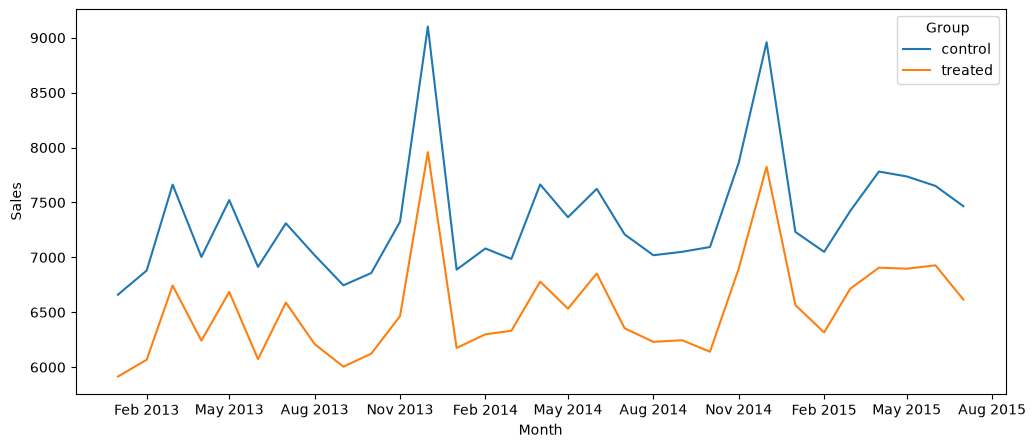

In [19]:
#LINE CHART
import matplotlib.dates as mdates #Tool to control Date axis.

plt.figure(figsize=(12, 5))

ax = sns.lineplot(data=monthly, x="Month", y="Sales", hue="Group")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3)) #Har 3 mahine m ek lable

ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y")) #Lable ka format “Jan 2013” jaisa rakho.

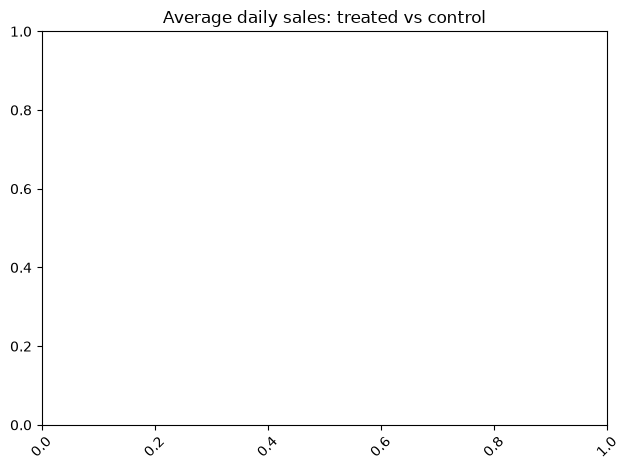

In [20]:
plt.title("Average daily sales: treated vs control")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [21]:
#Only weekdays lift 
wk = df[df["DayOfWeek"] <= 5] 

In [22]:
#Weekdays mein promo vs non-promo ka average, aur uska lift percent
avg = wk.groupby("Promo")["Sales"].mean()
print(round((avg[1] / avg[0] - 1) * 100, 1), "%")

38.8 %


In [23]:
# Har store ka apna lift
store_avg = wk.groupby(["Store", "Promo"])["Sales"].mean().unstack()

In [24]:
##Har store ka apna lift percentage
store_avg["lift_%"] = (store_avg[1] / store_avg[0] - 1) * 100

In [25]:
# All stores lifts summary: average, median, minimum, maximum.
print(store_avg["lift_%"].describe().round(1))

count    1115.0
mean       40.0
std        12.7
min         1.9
25%        31.3
50%        39.5
75%        47.6
max       102.1
Name: lift_%, dtype: float64


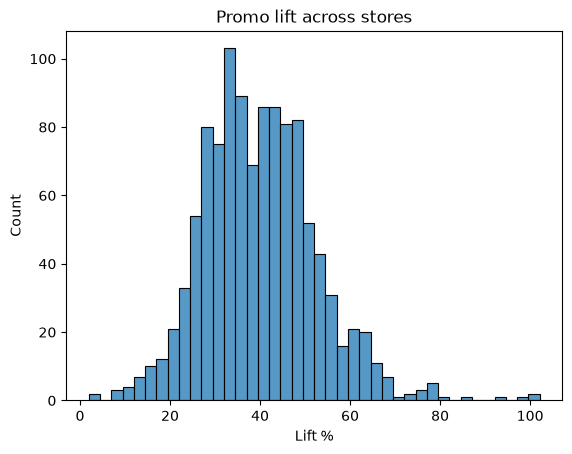

In [26]:
sns.histplot(store_avg["lift_%"], bins=40)
plt.title("Promo lift across stores")
plt.xlabel("Lift %")
plt.show()

In [27]:
#Cohort
cohort = usable[(usable["Promo2Start"] >= "2014-01-01") & (usable["Promo2Start"] <= "2014-06-30")]
print(len(cohort))

43


In [28]:
cohort_ids = cohort["Store"] #Storing the store numbers of the store

In [29]:
#Preparing data for did[data identifier]
did = df[df["Store"].isin(cohort_ids) | df["Store"].isin(control_ids)].copy() # | means "ya"


In [30]:
# Pehle sabko “control” likha, fir cohort wale stores ko “treated” kar diya.
did["Group"] = "control"
did.loc[did["Store"].isin(cohort_ids), "Group"] = "treated"

In [31]:
pre = did[(did["Date"] >= "2013-10-01") & (did["Date"] <= "2013-12-31")]
post = did[(did["Date"] >= "2014-10-01") & (did["Date"] <= "2014-12-31")]

In [32]:
#Har store ka pehle aur baad ka average
pre_avg = pre.groupby(["Store", "Group"])["Sales"].mean().reset_index(name="pre")
post_avg = post.groupby(["Store", "Group"])["Sales"].mean().reset_index(name="post")

In [33]:
#Dono ko ek table mein jod diya.
#Jis store ka kisi ek window mein data nahi tha (jaise lambe time band raha), wo apne aap hat gaya.

panel = pre_avg.merge(post_avg, on=["Store", "Group"])

In [34]:
panel["pct_change"] = (panel["post"] / panel["pre"] - 1) * 100

In [35]:
print(panel.groupby("Group")["Store"].count())

Group
control    520
treated     40
Name: Store, dtype: int64


In [36]:
#Dono groups average pre sales, post sales, and percent change in one table.
print(panel.groupby("Group")[["pre", "post", "pct_change"]].mean().round(1))

            pre    post  pct_change
Group                              
control  7689.2  7944.9         3.8
treated  7697.6  7916.8         4.6


In [37]:
#This is ur first DiD number : treated percent change minus control percent change. 
res = panel.groupby("Group")["pct_change"].mean()
print("DiD estimate (percentage points):", round(res["treated"] - res["control"], 1))

DiD estimate (percentage points): 0.8


In [38]:
from scipy import stats
t = panel[panel["Group"] == "treated"]["pct_change"]
c = panel[panel["Group"] == "control"]["pct_change"]
print(stats.ttest_ind(t, c, equal_var=False))

TtestResult(statistic=np.float64(0.38099027215650255), pvalue=np.float64(0.7052023761115473), df=np.float64(40.48750997627876))


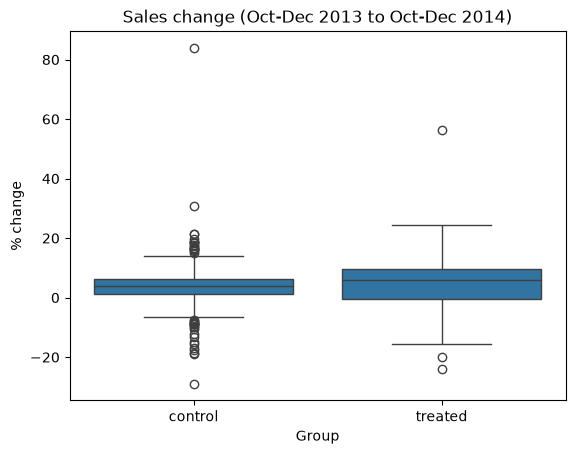

In [39]:
#BOX PLOT
sns.boxplot(data=panel, x="Group", y="pct_change")
plt.title("Sales change (Oct-Dec 2013 to Oct-Dec 2014)")
plt.ylabel("% change")
plt.show()

 #RESULTS 

#DID number
pre    post_change  pct_change
Group                              
control  7689.2  7944.9         3.8
treated  7697.6  7916.8         4.6

#Treated control kitne bche
Group
control    520
treated     40
Name: Store, dtype: int64

#Cohort 
43


In [41]:
#Mahine ke hisaab se sales index
did["Month"] = did["Date"].dt.to_period("M").dt.to_timestamp()

In [42]:
#Har mahine, har group (treated/control) average sales.
m = did.groupby(["Month", "Group"])["Sales"].mean().reset_index()

In [43]:
#Har group ki 2013 ki average sales (isse hum “100” maanenge).
base = m[m["Month"] < "2014-01-01"].groupby("Group")["Sales"].mean()

In [44]:
#Dono lines ko ek hi level (100) se shuru kar diya, taaki trend seedha compare ho sake
m["Index"] = m["Sales"] / m["Group"].map(base) * 100

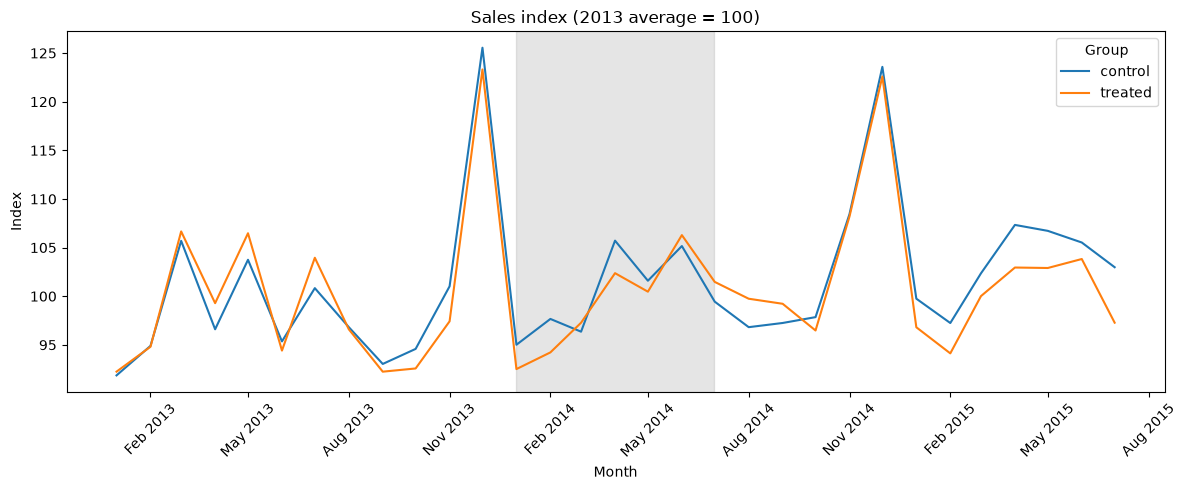

In [45]:
import matplotlib.dates as mdates

plt.figure(figsize=(12, 5))
ax = sns.lineplot(data=m, x="Month", y="Index", hue="Group")
plt.axvspan(pd.Timestamp("2014-01-01"), pd.Timestamp("2014-06-30"), alpha=0.2, color="grey")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.title("Sales index (2013 average = 100)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [46]:
#DID FUNCTION
from scipy import stats

def run_did(data, pre_start, pre_end, post_start, post_end):

#Dono windows ka data alag kiya
    pre = data[(data["Date"] >= pre_start) & (data["Date"] <= pre_end)]
    post = data[(data["Date"] >= post_start) & (data["Date"] <= post_end)]
    
# Har store ka pehle aur baad ka average.
    pre_avg = pre.groupby(["Store", "Group"])["Sales"].mean().reset_index(name="pre")
    post_avg = post.groupby(["Store", "Group"])["Sales"].mean().reset_index(name="post")

#find percentage by combining two
    panel = pre_avg.merge(post_avg, on=["Store", "Group"])
    panel["pct_change"] = (panel["post"] / panel["pre"] - 1) * 100

#Separate treated and control percentages
    t = panel.loc[panel["Group"] == "treated", "pct_change"]
    c = panel.loc[panel["Group"] == "control", "pct_change"]

#DiD estimate, p-value, aur dono groups ke stores ki ginti wapas karta hai.
    estimate = t.mean() - c.mean()
    p_value = stats.ttest_ind(t, c, equal_var=False).pvalue
    return round(estimate, 1), round(p_value, 4), len(t), len(c)

In [47]:
real = run_did(did, "2013-10-01", "2013-12-31", "2014-10-01", "2014-12-31")
print("Real DiD:", real)

placebo = run_did(did, "2013-01-01", "2013-03-31", "2013-10-01", "2013-12-31")
print("Placebo DiD:", placebo)

Real DiD: (np.float64(0.8), np.float64(0.7052), 40, 520)
Placebo DiD: (np.float64(3.0), np.float64(0.4903), 43, 541)


In [48]:
# ---------- Tools import karo ----------
import numpy as np                      # maths ke liye (log, exp)
import statsmodels.formula.api as smf   # regression chalane ke liye

# ---------- Step 1: Sirf treated aur control stores rakho ----------
reg = df[df["Group"].isin(["treated", "control"])].copy()   # "other" stores hata diye

# ---------- Step 1b (NAYA): Zero-sales din hatao ----------
# Store "open" tha par Sales = 0, ye data error hai. log(0) infinity banata hai, isliye hata do
print("Zero-sales din hataye:", (reg["Sales"] <= 0).sum())
reg = reg[reg["Sales"] > 0]

# ---------- Step 2: Treated stores ki Promo2 join date jodo ----------
reg = reg.merge(usable[["Store", "Promo2Start"]], on="Store", how="left")   # control stores ki date khali (NaT) rahegi

# ---------- Step 3: Har date ko uske mahine mein badlo ----------
reg["Month"] = reg["Date"].dt.to_period("M").dt.to_timestamp()   # jaise 2014-03-17 -> 2014-03-01

# ---------- Step 4: Har store ka har mahine ka average sales nikalo ----------
mdata = reg.groupby(["Store", "Month", "Group"]).agg(
    sales=("Sales", "mean"),            # us mahine ki average daily sales
    start=("Promo2Start", "first")      # store ki join date
).reset_index()                         # ab ek row = ek store, ek mahina

# ---------- Step 5: Sales ka log lo (taaki result percent mein mile) ----------
mdata["log_sales"] = np.log(mdata["sales"])

# ---------- Step 6: "Treatment" column banao ----------
# 1 tabhi hoga jab store treated hai AUR mahina join date ke baad ka hai, baaki sab 0
mdata["treat_post"] = ((mdata["Group"] == "treated") & (mdata["Month"] >= mdata["start"])).astype(int)

# ---------- Step 7: Check karo data sahi bana ya nahi ----------
print("Rows:", mdata.shape[0], "| treat_post=1 wali rows:", mdata["treat_post"].sum())
print("Infinite/NaN log values:", (~np.isfinite(mdata["log_sales"])).sum())   # 0 aana chahiye

# ---------- Step 8: Regression chalao ----------
# C(Store): har store ka apna alag level control ho jata hai
# C(Month): har mahine ka common trend (season, festival) control ho jata hai
# cluster: ek hi store ke mahine aapas mein related hote hain, isliye error sahi se ginta hai
model = smf.ols("log_sales ~ treat_post + C(Store) + C(Month)", data=mdata).fit(
    cov_type="cluster", cov_kwds={"groups": mdata["Store"]}
)

# ---------- Step 9: Promo2 ka asar aur uski range nikalo ----------
coef = model.params["treat_post"]               # asar (log scale mein)
ci = model.conf_int().loc["treat_post"]         # uski 95% range (log scale mein)

# ---------- Step 10: Result percent mein dikhao ----------
print("Effect:", round((np.exp(coef) - 1) * 100, 2), "%")
print("95% CI:", round((np.exp(ci.iloc[0]) - 1) * 100, 2), "to", round((np.exp(ci.iloc[1]) - 1) * 100, 2))
print("p-value:", round(model.pvalues["treat_post"], 4))

Zero-sales din hataye: 40
Rows: 21802 | treat_post=1 wali rows: 2831
Infinite/NaN log values: 0
Effect: 2.76 %
95% CI: 0.77 to 4.79
p-value: 0.0063


In [49]:
# ---------- Treated stores ki average daily sales ----------
avg_sales = df.loc[df["Group"] == "treated", "Sales"].mean()

# ---------- Teen scenarios: asar kam (CI low), best guess, zyada (CI high) ----------
effects = {
    "low": np.exp(ci.iloc[0]) - 1,       # confidence range ka neeche wala hissa
    "estimate": np.exp(coef) - 1,        # hamara main estimate
    "high": np.exp(ci.iloc[1]) - 1,      # confidence range ka upar wala hissa
}

# ---------- Maane gaye profit margins (ASSUMPTION, README mein likhna) ----------
margins = [0.15, 0.20, 0.25, 0.30]

# ---------- Har margin pe: promo se extra profit per store per din ----------
rows = []
for m in margins:
    row = {"margin_%": int(m * 100)}
    for name, eff in effects.items():
        row["extra_profit_per_day_" + name] = round(avg_sales * eff * m, 1)
    row["extra_profit_per_year_estimate"] = round(avg_sales * effects["estimate"] * m * 300, 0)   # 300 khule din maane
    rows.append(row)

be = pd.DataFrame(rows)

print("Avg daily sales (treated stores):", round(avg_sales, 0))
print(be.to_string(index=False))# ---------- Treated stores ki average daily sales ----------
avg_sales = df.loc[df["Group"] == "treated", "Sales"].mean()

# ---------- Teen scenarios: asar kam (CI low), best guess, zyada (CI high) ----------
effects = {
    "low": np.exp(ci.iloc[0]) - 1,       # confidence range ka neeche wala hissa
    "estimate": np.exp(coef) - 1,        # hamara main estimate
    "high": np.exp(ci.iloc[1]) - 1,      # confidence range ka upar wala hissa
}

# ---------- Maane gaye profit margins (ASSUMPTION, README mein likhna) ----------
margins = [0.15, 0.20, 0.25, 0.30]

# ---------- Har margin pe: promo se extra profit per store per din ----------
rows = []
for m in margins:
    row = {"margin_%": int(m * 100)}
    for name, eff in effects.items():
        row["extra_profit_per_day_" + name] = round(avg_sales * eff * m, 1)
    row["extra_profit_per_year_estimate"] = round(avg_sales * effects["estimate"] * m * 300, 0)   # 300 khule din maane
    rows.append(row)

be = pd.DataFrame(rows)

print("Avg daily sales (treated stores):", round(avg_sales, 0))
print(be.to_string(index=False))

Avg daily sales (treated stores): 6527.0
 margin_%  extra_profit_per_day_low  extra_profit_per_day_estimate  extra_profit_per_day_high  extra_profit_per_year_estimate
       15                       7.6                           27.0                       46.9                          8111.0
       20                      10.1                           36.0                       62.5                         10814.0
       25                      12.6                           45.1                       78.2                         13518.0
       30                      15.1                           54.1                       93.8                         16221.0
Avg daily sales (treated stores): 6527.0
 margin_%  extra_profit_per_day_low  extra_profit_per_day_estimate  extra_profit_per_day_high  extra_profit_per_year_estimate
       15                       7.6                           27.0                       46.9                          8111.0
       20                      10.1 

In [50]:
import os
import matplotlib.dates as mdates

# ---------- Folder banao jahan charts save honge ----------
os.makedirs("../reports/figures", exist_ok=True)

# ---------- Chart 1: Parallel trends (trend data dobara banaya) ----------
trend = did.groupby(["Month", "Group"])["Sales"].mean().reset_index()
base = trend[trend["Month"] < "2014-01-01"].groupby("Group")["Sales"].mean()
trend["Index"] = trend["Sales"] / trend["Group"].map(base) * 100

plt.figure(figsize=(12, 5))
ax = sns.lineplot(data=trend, x="Month", y="Index", hue="Group")
plt.axvspan(pd.Timestamp("2014-01-01"), pd.Timestamp("2014-06-30"), alpha=0.2, color="grey")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.title("Sales index (2013 average = 100); grey = Promo2 join window")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../reports/figures/01_parallel_trends.png", dpi=150)
plt.close()

# ---------- Chart 2: Daily Promo lift by weekday ----------
lift = by_day["lift_%"].dropna()
plt.figure(figsize=(7, 4))
sns.barplot(x=["Mon", "Tue", "Wed", "Thu", "Fri"], y=lift.values, color="steelblue")
plt.title("Daily Promo: sales lift by weekday (descriptive)")
plt.ylabel("Lift %")
plt.tight_layout()
plt.savefig("../reports/figures/02_promo_lift_by_weekday.png", dpi=150)
plt.close()

# ---------- Chart 3: Promo2 effect with confidence range ----------
eff = (np.exp(coef) - 1) * 100
lo = (np.exp(ci.iloc[0]) - 1) * 100
hi = (np.exp(ci.iloc[1]) - 1) * 100

plt.figure(figsize=(4, 4))
plt.errorbar([0], [eff], yerr=[[eff - lo], [hi - eff]], fmt="o", capsize=8)
plt.axhline(0, color="red", linestyle="--")
plt.xticks([0], ["Promo2 effect"])
plt.ylabel("% change in daily sales")
plt.title("Main estimate with 95% CI")
plt.tight_layout()
plt.savefig("../reports/figures/03_promo2_effect.png", dpi=150)
plt.close()

# ---------- Break-even table ko CSV mein save karo ----------
be.to_csv("../reports/break_even.csv", index=False)

print("Saved:", os.listdir("../reports/figures"))

Saved: ['01_parallel_trends.png', '02_promo_lift_by_weekday.png', '03_promo2_effect.png']


In [51]:
# ---------- Tools import karo ----------
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor   # ek tez tree-based ML model
from sklearn.metrics import r2_score, mean_absolute_error     # model kitna sahi hai, naapne ke liye
from sklearn.model_selection import train_test_split          # control stores ko train/test mein baantne ke liye

# ---------- Step 1: Har store ka "baseline" (Jan-Feb 2013 ki average log sales) ----------
# Yeh sabhi treated stores ke join se pehle ka period hai, isse model ko store ka apna level pata chalta hai
baseline = (mdata[mdata["Month"] <= "2013-02-01"]
            .groupby("Store")["log_sales"].mean()
            .rename("baseline").reset_index())

# ---------- Step 2: Features (model ke input) banao ----------
ml = mdata.merge(baseline, on="Store", how="inner")   # jin stores ka Jan-Feb data nahi, wo hat jayenge
ml = ml.merge(store[["Store", "StoreType", "Assortment", "CompetitionDistance"]], on="Store", how="left")
ml["t"] = (ml["Month"].dt.year - 2013) * 12 + ml["Month"].dt.month   # time trend (mahina number)
ml["month_num"] = ml["Month"].dt.month                               # season (1 se 12)
ml = pd.get_dummies(ml, columns=["StoreType", "Assortment"], dtype=int)   # text ko 0/1 columns mein badla
features = ["baseline", "t", "month_num", "CompetitionDistance"] + \
           [c for c in ml.columns if c.startswith("StoreType_") or c.startswith("Assortment_")]
print("Stores jo model mein hain:", ml["Store"].nunique(), "| features:", len(features))

# ---------- Step 3: Sirf control stores pe model sikhao ----------
control_ml = ml[ml["Group"] == "control"]
train_st, test_st = train_test_split(control_ml["Store"].unique(), test_size=0.2, random_state=42)   # 80% stores train, 20% test
train = control_ml[control_ml["Store"].isin(train_st)]
test = control_ml[control_ml["Store"].isin(test_st)]

model_ml = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=42)
model_ml.fit(train[features], train["log_sales"])

# ---------- Step 4: Model kitna achha hai? (jo stores usne dekhe hi nahi, unpe test) ----------
pred_test = model_ml.predict(test[features])
print("Test R2:", round(r2_score(test["log_sales"], pred_test), 3))                        # 1 ke jitna paas, utna achha
print("Test MAE (log):", round(mean_absolute_error(test["log_sales"], pred_test), 3))      # chhota = achha (0.05 matlab ~5% galti)

# ---------- Step 5: Ab saare control stores pe dobara sikhao (final model) ----------
model_ml.fit(control_ml[features], control_ml["log_sales"])

# ---------- Step 6: Treated stores ki sales predict karo ("Promo2 na hoti to") ----------
tr = ml[ml["Group"] == "treated"].copy()
tr["pred"] = model_ml.predict(tr[features])
tr["resid"] = tr["log_sales"] - tr["pred"]          # asli minus predicted (log mein)

# ---------- Step 7: Har store ka "join ke pehle" aur "join ke baad" ka average farak ----------
store_eff = tr.groupby(["Store", "treat_post"])["resid"].mean().unstack().dropna()   # sirf wo stores jinka pehle aur baad dono data hai
store_eff["effect"] = store_eff[1] - store_eff[0]   # baad ka farak minus pehle ka farak (model ki chhoti galti hat jati hai)

print("Pre-join average residual (0 ke paas hona chahiye):", round(store_eff[0].mean(), 4))
print("Stores jinka asar nikala:", len(store_eff))

# ---------- Step 8: Final asar aur uski range (bootstrap) ----------
eff = store_eff["effect"].values
point = (np.exp(eff.mean()) - 1) * 100

rng = np.random.default_rng(42)
boots = rng.choice(eff, size=(1000, len(eff)), replace=True).mean(axis=1)   # stores ko 1000 baar random chun ke dobara average
lo, hi = np.percentile(boots, [2.5, 97.5])

print("ML counterfactual effect:", round(point, 2), "%")
print("95% CI:", round((np.exp(lo) - 1) * 100, 2), "to", round((np.exp(hi) - 1) * 100, 2))
print("Regression estimate (compare ke liye): 2.76 %, CI 0.77 to 4.79")

Stores jo model mein hain: 717 | features: 11
Test R2: 0.914
Test MAE (log): 0.068
Pre-join average residual (0 ke paas hona chahiye): -0.0104
Stores jinka asar nikala: 176
ML counterfactual effect: 1.78 %
95% CI: -0.08 to 3.57
Regression estimate (compare ke liye): 2.76 %, CI 0.77 to 4.79


#Important

Naive Promo lift: 38.8%
Promo lift by weekday: Mon 57%, Tue 45%, Wed 37%, Thu 32%, Fri 22%
2x2 DiD: +0.8 pp, p = 0.71 (40 treated stores)
Placebo: +3.0 pp, p = 0.49
Main regression: +2.76%, CI 0.77 to 4.79, p = 0.0063 (176 treated stores)
ML check: +1.78%, CI -0.08 to 3.57 (R2 0.914)

In [53]:
import os
os.makedirs("../reports/dashboard_data", exist_ok=True)   # folder banao

# ---------- 1. Parallel-trends data (Month, Group, Index) ----------
trend.to_csv("../reports/dashboard_data/trend.csv", index=False)

# ---------- 2. Weekday ka lift (sirf Mon-Fri, jahan promo chali) ----------
wd = by_day.reset_index()[["DayOfWeek", "lift_%"]].dropna()
wd["Day"] = wd["DayOfWeek"].map({1: "Mon", 2: "Tue", 3: "Wed", 4: "Thu", 5: "Fri"})
wd.to_csv("../reports/dashboard_data/weekday_lift.csv", index=False)

# ---------- 3. Break-even table ----------
be.to_csv("../reports/dashboard_data/break_even.csv", index=False)

# ---------- 4. Headline numbers (regression wale coef aur ci se) ----------
summary = pd.DataFrame({
    "metric": ["Naive promo lift %", "Promo2 effect % (regression)", "CI low %", "CI high %",
               "ML check effect %", "ML CI low %", "ML CI high %"],
    "value": [round(naive_lift, 1),
              round((np.exp(coef) - 1) * 100, 2),
              round((np.exp(ci.iloc[0]) - 1) * 100, 2),
              round((np.exp(ci.iloc[1]) - 1) * 100, 2),
              1.78, -0.08, 3.57]      # ML ke numbers tumhare output se
})
summary.to_csv("../reports/dashboard_data/summary.csv", index=False)

print(os.listdir("../reports/dashboard_data"))

['break_even.csv', 'summary.csv', 'trend.csv', 'weekday_lift.csv']


In [54]:
import os
print(os.path.abspath("../reports/dashboard_data"))

C:\Users\user\Desktop\reports\dashboard_data
